In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import root_numpy

Welcome to JupyROOT 6.22/02


In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

In [3]:
def getData(branchNames, dfNames, inputFiles, treeName):
    data = root_numpy.root2array(inputFiles, treeName, branches=branchNames)
    return pd.DataFrame(data, columns=dfNames)

In [111]:
def flatten(data, column):
    print('column:', column)
    a = []
    if (column != 7):
        for row in range(0,len(data)):
            if (len(data[row]['pt']) > 0): 
                a.append(data[row][column][0]) # caveat: only including leading jets
    else:
        for row in range(0,len(data)):
            if (len(data[row]['pt']) > 0): 
                a.append(data[row][column])
    b = np.asarray(a)
    b.astype('float32')
    return b

In [112]:
def getFlattenedData(branchNames, dfNames, inputFiles, treeName):
    data = root_numpy.root2array(inputFiles, treeName, branches=branchNames)
    a = []
    for branchName in branchNames:
        a.append(flatten(data, branchNames.index(branchName)))
    return pd.DataFrame(np.transpose(a), columns=dfNames)

In [127]:
def getRc(dataframe):
    n_ss = sum(dataframe[dataframe.b==1]['weight'])
    n_os = sum(dataframe[dataframe.b==-1]['weight'])
    return (n_ss-n_os)/(n_ss+n_os)

In [7]:
observables2 = ['pt','m','b','dr','rg','zg','mg','weight']#,'evid','reject']
observabless2 = ['pts','ms','bs','drs','rgs','zgs','mgs','ws','evids','rejects']

In [113]:
data = root_numpy.root2array('$HOME/output/run12/pythia0412.root', 'ResultTree', branches=observables2)
a = []
for branchName in observables2:
    print(branchName)
    a.append(flatten(data, observables2.index(branchName)))

pt
column: 0
m
column: 1
b
column: 2
dr
column: 3
rg
column: 4
zg
column: 5
mg
column: 6
weight
column: 7


In [101]:
len(a[-1])

408549

In [100]:
len(a[0])

543087

In [138]:
df = pd.DataFrame(np.transpose(a), columns=observables2, dtype='float32')

In [115]:
df

,pt,m,b,dr,rg,zg,mg,weight
0,9.715593,1.467552,0.0,0.337906,0.247254,0.489651,1.467552,1.437899e-08
1,9.281890,4.324058,-1.0,0.340494,0.390558,0.118418,4.324058,1.437899e-08
2,11.141212,3.146468,0.0,0.397718,0.277500,0.282812,3.146468,1.437899e-08
3,9.691874,2.623642,1.0,0.098019,0.215357,0.418913,2.623642,1.437899e-08
4,14.375233,2.930389,0.0,0.486179,0.374811,0.111747,2.930389,1.437899e-08
...,...,...,...,...,...,...,...,...
408544,9.652469,2.947321,0.0,0.250866,0.210939,0.204720,2.947321,1.946740e-08
408545,10.169686,2.240417,0.0,0.699947,0.395829,0.258534,2.240417,1.946740e-08
408546,7.248245,2.694241,0.0,0.381345,0.193745,0.332202,2.504926,1.946740e-08
408547,5.574698,1.963632,0.0,0.465613,0.372635,0.160108,1.963632,1.946740e-08


In [139]:
df = applyCut(df, 'b!=0')

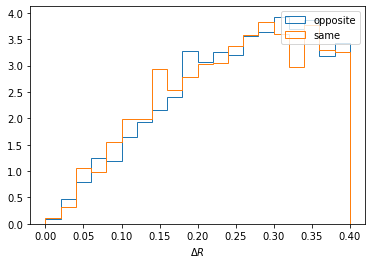

In [140]:
plt.hist(df[df.b<0]['dr'], histtype='step', label='opposite', bins=np.arange(0,0.42,0.02), density=True, weights=df[df.b<0]['weight'])
plt.hist(df[df.b>0]['dr'], histtype='step', label='same', bins=np.arange(0,0.42,0.02), density=True, weights=df[df.b>0]['weight'])
plt.xlabel('$\Delta R$')
plt.legend()

In [141]:
dredges = np.arange(0,0.42,0.02)
drcenter = np.arange(0.01,0.41,0.02)

In [142]:
dfs = []
for i in range(0, len(drcenter)):
    dfs.append(df[np.logical_and(df.dr>dredges[i], df.dr<dredges[i+1])])

In [143]:
rcs = []
for i in range(0, len(dfs)):
    rcs.append(getRc(dfs[i]))

In [144]:
rcs

[-0.17180495255867484,
 -0.41764910207226874,
 -0.10653342410521999,
 -0.35860033159462434,
 -0.11925769998426623,
 -0.1504906481466852,
 -0.2324988739784036,
 -0.09543240891311862,
 -0.21977080977582436,
 -0.31761696313774856,
 -0.25041736908784207,
 -0.27503870405000697,
 -0.2192331049875865,
 -0.24303500364437022,
 -0.22033535235103532,
 -0.2847786239524395,
 -0.3446969938994679,
 -0.2574777468219505,
 -0.22992331432620572,
 -0.2698161988672408]

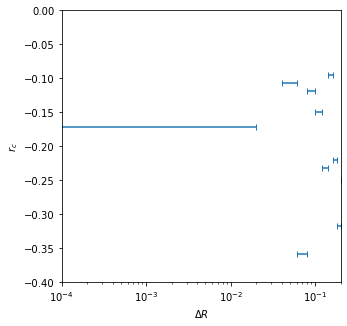

In [145]:
fig=plt.figure(figsize=(5,5))
plt.errorbar(drcenter, rcs, xerr=np.array(drcenter)-np.array(dredges[:-1]), ls='none', capsize=3)
plt.xlabel('$\Delta R$')
plt.ylabel('$r_c$')
plt.xlim(0.0001,0.2)
plt.ylim(-0.4,0)
plt.xscale('log')